In [1]:
import torchvision as tv
from torchvision import models, transforms
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, ConcatDataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

def show_comparison(experiment, strategy, model, optimizer,
                    history, best_epoch, training_time, y_true, y_pred):

    results = {
        "Eksperimen": experiment,
        "Strategi": strategy,
        "Trainable Params": sum(
            p.numel() for p in model.parameters() if p.requires_grad
        ),
        "Learning Rate": ", ".join(
            str(g["lr"]) for g in optimizer.param_groups
        ),
        "Epoch Konvergen": best_epoch,
        "Waktu Training (s)": round(training_time, 2),
        "Validation Accuracy": f"{history['val_acc'][best_epoch-1]:.2%}",
        "Macro F1 Test": round(
            f1_score(y_true, y_pred, average="macro"), 4
        )
    }

    display(pd.DataFrame([results]))

    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(8, 4))
    plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
    plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
    plt.axvline(best_epoch, linestyle="--", label=f"Best Epoch: {best_epoch}")

    plt.title(f"{experiment} - {strategy}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results

In [3]:
seed = 42
dataset = tv.datasets.oxford_iiit_pet.OxfordIIITPet(download=True, root=".")

100%|██████████| 792M/792M [00:35<00:00, 22.2MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 11.7MB/s]


In [4]:
selected_classes = [
    # Kucing (5 Ras)
    "Abyssinian",
    "Bengal",
    "Maine Coon",
    "Persian",
    "Siamese",
    # Anjing (5 Ras)
    "Beagle",
    "Boxer",
    "Chihuahua",
    "Pug",
    "Shiba Inu",
]
print("classes: \n - %s\nTotal Classes: %d\nSelected: %d" % ("\n - ".join(dataset.classes), len(dataset.classes), len(selected_classes)))


classes: 
 - Abyssinian
 - American Bulldog
 - American Pit Bull Terrier
 - Basset Hound
 - Beagle
 - Bengal
 - Birman
 - Bombay
 - Boxer
 - British Shorthair
 - Chihuahua
 - Egyptian Mau
 - English Cocker Spaniel
 - English Setter
 - German Shorthaired
 - Great Pyrenees
 - Havanese
 - Japanese Chin
 - Keeshond
 - Leonberger
 - Maine Coon
 - Miniature Pinscher
 - Newfoundland
 - Persian
 - Pomeranian
 - Pug
 - Ragdoll
 - Russian Blue
 - Saint Bernard
 - Samoyed
 - Scottish Terrier
 - Shiba Inu
 - Siamese
 - Sphynx
 - Staffordshire Bull Terrier
 - Wheaten Terrier
 - Yorkshire Terrier
Total Classes: 37
Selected: 10


### **1. B2**

In [5]:
# 1. Inisialisasi Model ResNet-18 dengan Pre-trained Weights dari ImageNet
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    ),
])
eval_transforms = weights.transforms()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 142MB/s]


In [6]:
from torch.utils.data import Dataset

# Dataset tanpa transform
trainval = tv.datasets.OxfordIIITPet(
    root="./data", split="trainval",
    download=True
)

test = tv.datasets.OxfordIIITPet(
    root="./data", split="test",
    download=True
)

dataset = ConcatDataset([trainval, test])

# Pilih 10 kelas dari selected_classes
selected_ids = [
    trainval.class_to_idx[name]
    for name in selected_classes
]

label_map = {
    old_id: new_id
    for new_id, old_id in enumerate(selected_ids)
}

indices = []
labels = []

for i in range(len(dataset)):
    _, label = dataset[i]

    if label in label_map:
        indices.append(i)
        labels.append(label_map[label])

# Split 70/15/15
train_idx, temp_idx = sk.model_selection.train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

temp_labels = [
    label_map[dataset[i][1]]
    for i in temp_idx
]

val_idx, test_idx = sk.model_selection.train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

# Dataset dengan transform masing-masing
class PetSubset(Dataset):
    def __init__(self, dataset, indices, transform):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image, label = self.dataset[self.indices[idx]]
        image = self.transform(image)
        return image, label_map[label]

train_dataset = PetSubset(dataset, train_idx, train_transforms)
val_dataset = PetSubset(dataset, val_idx, eval_transforms)
test_dataset = PetSubset(dataset, test_idx, eval_transforms)

# DataLoader
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

100%|██████████| 792M/792M [00:58<00:00, 13.5MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.38MB/s]


Train: 1397
Validation: 299
Test: 300


In [7]:
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Labels:", labels)
print("Min label:", labels.min().item())
print("Max label:", labels.max().item())

Image shape: torch.Size([32, 3, 224, 224])
Labels: tensor([7, 3, 6, 8, 4, 2, 7, 7, 3, 7, 8, 5, 6, 3, 2, 8, 4, 1, 3, 2, 4, 4, 0, 4,
        0, 0, 5, 2, 4, 7, 7, 4])
Min label: 0
Max label: 8


In [8]:
# Freeze seluruh backbone
for param in model.parameters():
    param.requires_grad = False

# Classifier 10 kelas
model.fc = nn.Linear(model.fc.in_features, 10)

# # Unfreeze layer4
# for param in model.layer4.parameters():
#     param.requires_grad = True

# Cek trainable parameters
print("Trainable:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))


Trainable: 5130


In [9]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Device:", device)

Device: cuda


In [10]:
import time
import copy

epochs = 20
patience = 4
best_val_loss = float("inf")
counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_weights = copy.deepcopy(model.state_dict())
start_time = time.time()

for epoch in range(epochs):

    # TRAINING
    # B2: Backbone BatchNorm tetap menggunakan pretrained statistics
    model.eval()

    train_loss = 0
    train_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct / len(train_loader.dataset)

    # VALIDATION
    model.eval()

    val_loss = 0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct / len(val_loader.dataset)

    # SAVE METRICS
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    # EARLY STOPPING
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_weights)

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

Epoch 01/20 | Train Loss: 1.3018 | Train Acc: 65.28% | Val Loss: 0.5413 | Val Acc: 90.97%
Epoch 02/20 | Train Loss: 0.4687 | Train Acc: 91.41% | Val Loss: 0.3206 | Val Acc: 92.64%
Epoch 03/20 | Train Loss: 0.3265 | Train Acc: 93.41% | Val Loss: 0.2249 | Val Acc: 96.99%
Epoch 04/20 | Train Loss: 0.2672 | Train Acc: 94.85% | Val Loss: 0.2145 | Val Acc: 94.65%
Epoch 05/20 | Train Loss: 0.2258 | Train Acc: 95.56% | Val Loss: 0.1755 | Val Acc: 96.66%
Epoch 06/20 | Train Loss: 0.2113 | Train Acc: 94.63% | Val Loss: 0.1762 | Val Acc: 95.65%
Epoch 07/20 | Train Loss: 0.1799 | Train Acc: 95.92% | Val Loss: 0.1456 | Val Acc: 96.99%
Epoch 08/20 | Train Loss: 0.1661 | Train Acc: 96.35% | Val Loss: 0.1531 | Val Acc: 93.98%
Epoch 09/20 | Train Loss: 0.1462 | Train Acc: 96.85% | Val Loss: 0.1367 | Val Acc: 96.66%
Epoch 10/20 | Train Loss: 0.1441 | Train Acc: 96.56% | Val Loss: 0.1268 | Val Acc: 95.65%
Epoch 11/20 | Train Loss: 0.1317 | Train Acc: 97.35% | Val Loss: 0.1354 | Val Acc: 96.66%
Epoch 12/2

,Eksperimen,Strategi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Training (s),Validation Accuracy,Macro F1 Test
0,B2,Feature Extraction,5130,0.001,19,329.07,97.66%,0.9476


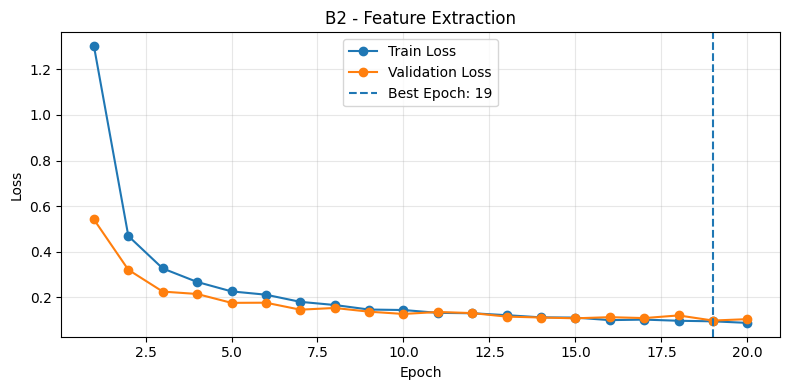

In [11]:
model.eval()

y_true = []
y_pred = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())
result_B2 = show_comparison(
    "B2", "Feature Extraction",
    model, optimizer, history, best_epoch,
    training_time, y_true, y_pred
)

#### **B1**

In [12]:
# B1: ResNet18 From Scratch
model = models.resnet18(weights=None)

# Ganti classifier menjadi 10 kelas
model.fc = nn.Linear(model.fc.in_features, 10)

# Semua parameter trainable
for param in model.parameters():
    param.requires_grad = True

model = model.to(device)

print("Trainable:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))

Trainable: 11181642


In [13]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

In [14]:
import time
import copy

epochs = 20
patience = 4
best_val_loss = float("inf")
counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_weights = copy.deepcopy(model.state_dict())
start_time = time.time()

for epoch in range(epochs):

    # TRAINING B1: Semua layer dilatih
    model.train()

    train_loss = 0
    train_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct / len(train_loader.dataset)

    # VALIDATION
    model.eval()

    val_loss = 0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct / len(val_loader.dataset)

    # SAVE METRICS
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    # EARLY STOPPING
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_weights)

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

Epoch 01/20 | Train Loss: 2.4240 | Train Acc: 17.11% | Val Loss: 3.9245 | Val Acc: 14.38%
Epoch 02/20 | Train Loss: 2.1943 | Train Acc: 22.33% | Val Loss: 2.3702 | Val Acc: 13.71%
Epoch 03/20 | Train Loss: 2.1057 | Train Acc: 24.70% | Val Loss: 2.1976 | Val Acc: 25.42%
Epoch 04/20 | Train Loss: 2.0264 | Train Acc: 26.13% | Val Loss: 2.2475 | Val Acc: 25.75%
Epoch 05/20 | Train Loss: 1.9607 | Train Acc: 30.35% | Val Loss: 1.8851 | Val Acc: 32.11%
Epoch 06/20 | Train Loss: 1.9158 | Train Acc: 32.07% | Val Loss: 1.8151 | Val Acc: 34.45%
Epoch 07/20 | Train Loss: 1.8087 | Train Acc: 35.43% | Val Loss: 1.9740 | Val Acc: 28.43%
Epoch 08/20 | Train Loss: 1.7449 | Train Acc: 39.23% | Val Loss: 1.9868 | Val Acc: 31.77%
Epoch 09/20 | Train Loss: 1.6892 | Train Acc: 39.87% | Val Loss: 1.8321 | Val Acc: 39.46%
Epoch 10/20 | Train Loss: 1.6242 | Train Acc: 44.02% | Val Loss: 1.9696 | Val Acc: 33.44%
Early stopping triggered!

Best Epoch: 6
Best Validation Loss: 1.8151
Training Time: 184.85 seconds


,Eksperimen,Strategi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Training (s),Validation Accuracy,Macro F1 Test
0,B1,From Scratch,11181642,0.001,6,184.85,34.45%,0.322


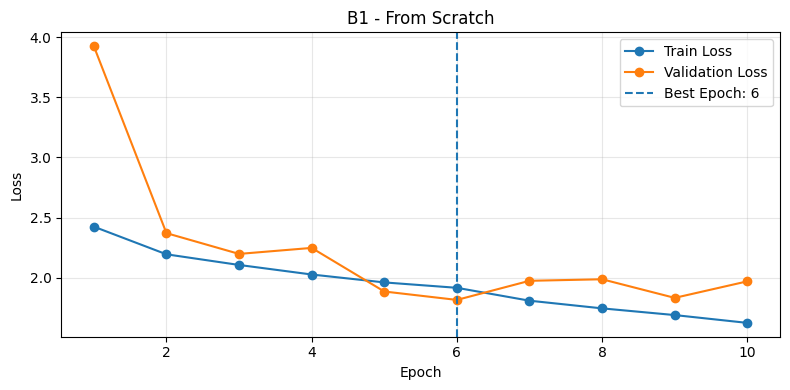

In [15]:
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

result_B1 = show_comparison(
    "B1",
    "From Scratch",
    model,
    optimizer,
    history,
    best_epoch,
    training_time,
    y_true,
    y_pred
)

#### **B3**

In [34]:
# B3: Progressive Fine-Tuning
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

# Freeze semua parameter
for param in model.parameters():
    param.requires_grad = False

# Ganti classifier menjadi 10 kelas
model.fc = nn.Linear(model.fc.in_features, 10)

# Unfreeze layer4
for param in model.layer4.parameters():
    param.requires_grad = True

model = model.to(device)

print("Trainable:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))

Trainable: 8398858


In [35]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

In [36]:
import time
import copy

epochs = 20
patience = 4
best_val_loss = float("inf")
best_epoch = 0
counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_weights = copy.deepcopy(model.state_dict())
start_time = time.time()

for epoch in range(epochs):

    # TRAINING B3: Progressive Fine-Tuning
    model.train()

    # Frozen backbone menggunakan pretrained BatchNorm statistics
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()

    train_loss = 0
    train_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct / len(train_loader.dataset)

    # VALIDATION
    model.eval()

    val_loss = 0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct / len(val_loader.dataset)

    # SAVE METRICS
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    # EARLY STOPPING
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_weights)

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

Epoch 01/20 | Train Loss: 0.7762 | Train Acc: 79.74% | Val Loss: 0.1709 | Val Acc: 95.32%
Epoch 02/20 | Train Loss: 0.1733 | Train Acc: 95.28% | Val Loss: 0.1388 | Val Acc: 95.99%
Epoch 03/20 | Train Loss: 0.0979 | Train Acc: 97.64% | Val Loss: 0.1171 | Val Acc: 96.32%
Epoch 04/20 | Train Loss: 0.0625 | Train Acc: 98.57% | Val Loss: 0.1137 | Val Acc: 95.99%
Epoch 05/20 | Train Loss: 0.0374 | Train Acc: 99.28% | Val Loss: 0.1097 | Val Acc: 96.99%
Epoch 06/20 | Train Loss: 0.0315 | Train Acc: 99.28% | Val Loss: 0.1203 | Val Acc: 96.32%
Epoch 07/20 | Train Loss: 0.0198 | Train Acc: 99.79% | Val Loss: 0.1017 | Val Acc: 96.66%
Epoch 08/20 | Train Loss: 0.0135 | Train Acc: 99.93% | Val Loss: 0.1247 | Val Acc: 96.32%
Epoch 09/20 | Train Loss: 0.0124 | Train Acc: 99.79% | Val Loss: 0.1214 | Val Acc: 95.99%
Epoch 10/20 | Train Loss: 0.0187 | Train Acc: 99.64% | Val Loss: 0.1343 | Val Acc: 95.99%
Epoch 11/20 | Train Loss: 0.0186 | Train Acc: 99.64% | Val Loss: 0.1410 | Val Acc: 97.32%
Early stop

,Eksperimen,Strategi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Training (s),Validation Accuracy,Macro F1 Test
0,B3,Progressive Fine-Tuning,8398858,"0.0001, 0.001",7,186.97,96.66%,0.9498


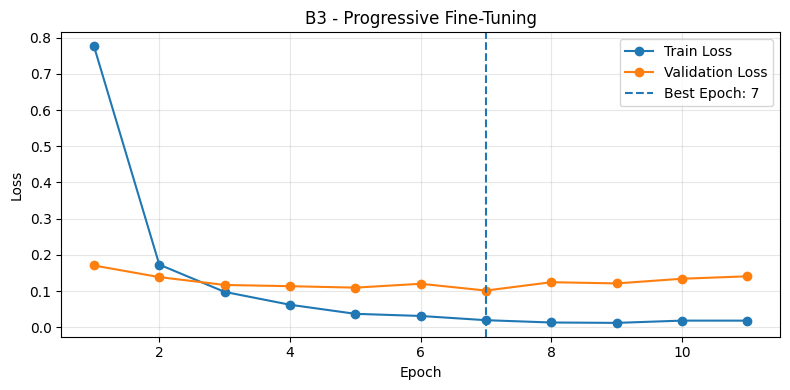

In [37]:
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())
result_B3 = show_comparison(
    "B3",
    "Progressive Fine-Tuning",
    model,
    optimizer,
    history,
    best_epoch,
    training_time,
    y_true,
    y_pred
)

In [38]:
torch.save(model.state_dict(), "resnet18_b3_finetuned.pth")

#### **B4**

In [20]:
# B4: Training tanpa augmentation
train_noaug_dataset = PetSubset(
    dataset, train_idx, eval_transforms
)

train_noaug_loader = DataLoader(
    train_noaug_dataset,
    batch_size=32,
    shuffle=True
)

print("Train without augmentation:", len(train_noaug_dataset))

Train without augmentation: 1397


In [21]:
# B4: B3 tanpa augmentation
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

# Freeze backbone
for param in model.parameters():
    param.requires_grad = False

# Classifier 10 kelas
model.fc = nn.Linear(model.fc.in_features, 10)

# Unfreeze layer4
for param in model.layer4.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

print("Trainable:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))

Trainable: 8398858


In [22]:
import time
import copy

epochs = 20
patience = 4
best_val_loss = float("inf")
best_epoch = 0
counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_weights = copy.deepcopy(model.state_dict())
start_time = time.time()

for epoch in range(epochs):

    # TRAINING B4: Fine-Tuning WITHOUT Augmentation
    model.train()

    # Frozen backbone menggunakan pretrained BatchNorm statistics
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()

    train_loss = 0
    train_correct = 0

    # B4: Data training tanpa augmentasi
    for images, labels in train_noaug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    train_loss /= len(train_noaug_loader.dataset)
    train_acc = train_correct / len(train_noaug_loader.dataset)

    # VALIDATION
    model.eval()

    val_loss = 0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct / len(val_loader.dataset)

    # SAVE METRICS
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    # EARLY STOPPING
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_weights)

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

Epoch 01/20 | Train Loss: 0.6288 | Train Acc: 83.46% | Val Loss: 0.1626 | Val Acc: 93.31%
Epoch 02/20 | Train Loss: 0.0796 | Train Acc: 98.50% | Val Loss: 0.1084 | Val Acc: 96.99%
Epoch 03/20 | Train Loss: 0.0280 | Train Acc: 99.86% | Val Loss: 0.1201 | Val Acc: 95.99%
Epoch 04/20 | Train Loss: 0.0123 | Train Acc: 100.00% | Val Loss: 0.1196 | Val Acc: 95.99%
Epoch 05/20 | Train Loss: 0.0071 | Train Acc: 100.00% | Val Loss: 0.1131 | Val Acc: 96.32%
Epoch 06/20 | Train Loss: 0.0048 | Train Acc: 100.00% | Val Loss: 0.1117 | Val Acc: 96.32%
Early stopping triggered!

Best Epoch: 2
Best Validation Loss: 0.1084
Training Time: 75.09 seconds


,Eksperimen,Strategi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Training (s),Validation Accuracy,Macro F1 Test
0,B4,Fine-Tuning Without Augmentation,8398858,"0.0001, 0.001",2,75.09,96.99%,0.957


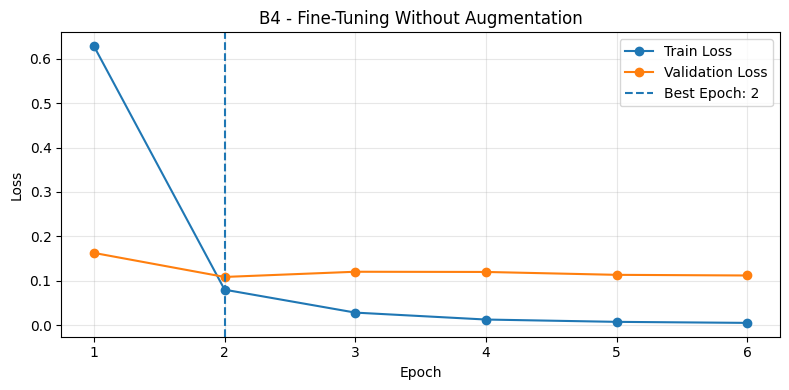

In [23]:
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())
result_B4 = show_comparison(
    "B4",
    "Fine-Tuning Without Augmentation",
    model,
    optimizer,
    history,
    best_epoch,
    training_time,
    y_true,
    y_pred
)

In [24]:
comparison_aug = pd.DataFrame([
    result_B3,
    result_B4
])

display(comparison_aug)

,Eksperimen,Strategi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Training (s),Validation Accuracy,Macro F1 Test
0,B3,Progressive Fine-Tuning,8398858,"0.0001, 0.001",6,168.96,96.66%,0.9367
1,B4,Fine-Tuning Without Augmentation,8398858,"0.0001, 0.001",2,75.09,96.99%,0.9570


In [25]:
gap_b4 = (
    history["train_acc"][best_epoch - 1]
    - history["val_acc"][best_epoch - 1]
)

print(f"B4 Generalization Gap: {gap_b4:.2%}")

B4 Generalization Gap: 1.51%


#### **B5**

In [26]:
# B5: EfficientNet-B0 Fine-Tuning
weights_b5 = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=weights_b5)

# Freeze semua parameter
for param in model.parameters():
    param.requires_grad = False

# Ganti classifier menjadi 10 kelas
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 10
)

# Unfreeze blok fitur terakhir
for param in model.features[-1].parameters():
    param.requires_grad = True

model = model.to(device)

print("Total Parameters:", sum(
    p.numel() for p in model.parameters()
))

print("Trainable Parameters:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 110MB/s] 


Total Parameters: 4020358
Trainable Parameters: 424970


In [27]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {"params": model.features[-1].parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

In [28]:
import time
import copy

epochs = 20
patience = 4
best_val_loss = float("inf")
best_epoch = 0
counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_weights = copy.deepcopy(model.state_dict())
start_time = time.time()

for epoch in range(epochs):

    # TRAINING B5: EfficientNet-B0 Fine-Tuning
    model.train()

    # Frozen backbone menggunakan pretrained BatchNorm statistics
    model.features[:-1].eval()

    # Blok terakhir dan classifier tetap training
    model.features[-1].train()
    model.classifier.train()

    train_loss = 0
    train_correct = 0

    # B5: Training tanpa augmentation (sama seperti B4)
    for images, labels in train_noaug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    train_loss /= len(train_noaug_loader.dataset)
    train_acc = train_correct / len(train_noaug_loader.dataset)

    # VALIDATION
    model.eval()

    val_loss = 0
    val_correct = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct / len(val_loader.dataset)

    # SAVE METRICS
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    # EARLY STOPPING
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_weights)

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

Epoch 01/20 | Train Loss: 0.8327 | Train Acc: 88.05% | Val Loss: 0.1901 | Val Acc: 97.32%
Epoch 02/20 | Train Loss: 0.1603 | Train Acc: 97.42% | Val Loss: 0.1015 | Val Acc: 97.99%
Epoch 03/20 | Train Loss: 0.0990 | Train Acc: 98.14% | Val Loss: 0.0775 | Val Acc: 97.99%
Epoch 04/20 | Train Loss: 0.0728 | Train Acc: 98.64% | Val Loss: 0.0699 | Val Acc: 97.66%
Epoch 05/20 | Train Loss: 0.0547 | Train Acc: 99.14% | Val Loss: 0.0631 | Val Acc: 97.66%
Epoch 06/20 | Train Loss: 0.0439 | Train Acc: 99.28% | Val Loss: 0.0576 | Val Acc: 97.66%
Epoch 07/20 | Train Loss: 0.0352 | Train Acc: 99.36% | Val Loss: 0.0582 | Val Acc: 97.66%
Epoch 08/20 | Train Loss: 0.0276 | Train Acc: 99.71% | Val Loss: 0.0560 | Val Acc: 97.99%
Epoch 09/20 | Train Loss: 0.0224 | Train Acc: 99.71% | Val Loss: 0.0549 | Val Acc: 97.66%
Epoch 10/20 | Train Loss: 0.0202 | Train Acc: 99.57% | Val Loss: 0.0534 | Val Acc: 97.32%
Epoch 11/20 | Train Loss: 0.0153 | Train Acc: 99.86% | Val Loss: 0.0538 | Val Acc: 97.66%
Epoch 12/2

In [29]:

model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

,Eksperimen,Strategi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Training (s),Validation Accuracy,Macro F1 Test
0,B5,EfficientNet-B0 Fine-Tuning,424970,"0.0001, 0.001",10,181.35,97.32%,0.9732


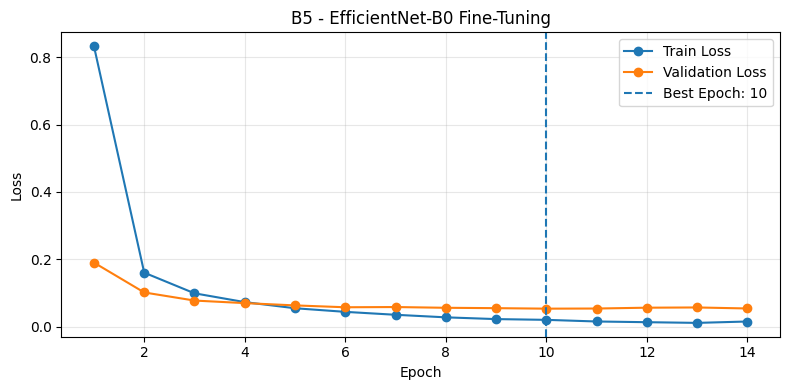

In [30]:
result_B5 = show_comparison(
    "B5",
    "EfficientNet-B0 Fine-Tuning",
    model,
    optimizer,
    history,
    best_epoch,
    training_time,
    y_true,
    y_pred
)

In [31]:
comparison_df = pd.DataFrame([
    result_B1,
    result_B2,
    result_B3,
    result_B4,
    result_B5
])

display(comparison_df)

,Eksperimen,Strategi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Training (s),Validation Accuracy,Macro F1 Test
0,B1,From Scratch,11181642,0.001,6,184.85,34.45%,0.3220
1,B2,Feature Extraction,5130,0.001,19,329.07,97.66%,0.9476
2,B3,Progressive Fine-Tuning,8398858,"0.0001, 0.001",6,168.96,96.66%,0.9367
3,B4,Fine-Tuning Without Augmentation,8398858,"0.0001, 0.001",2,75.09,96.99%,0.9570
4,B5,EfficientNet-B0 Fine-Tuning,424970,"0.0001, 0.001",10,181.35,97.32%,0.9732


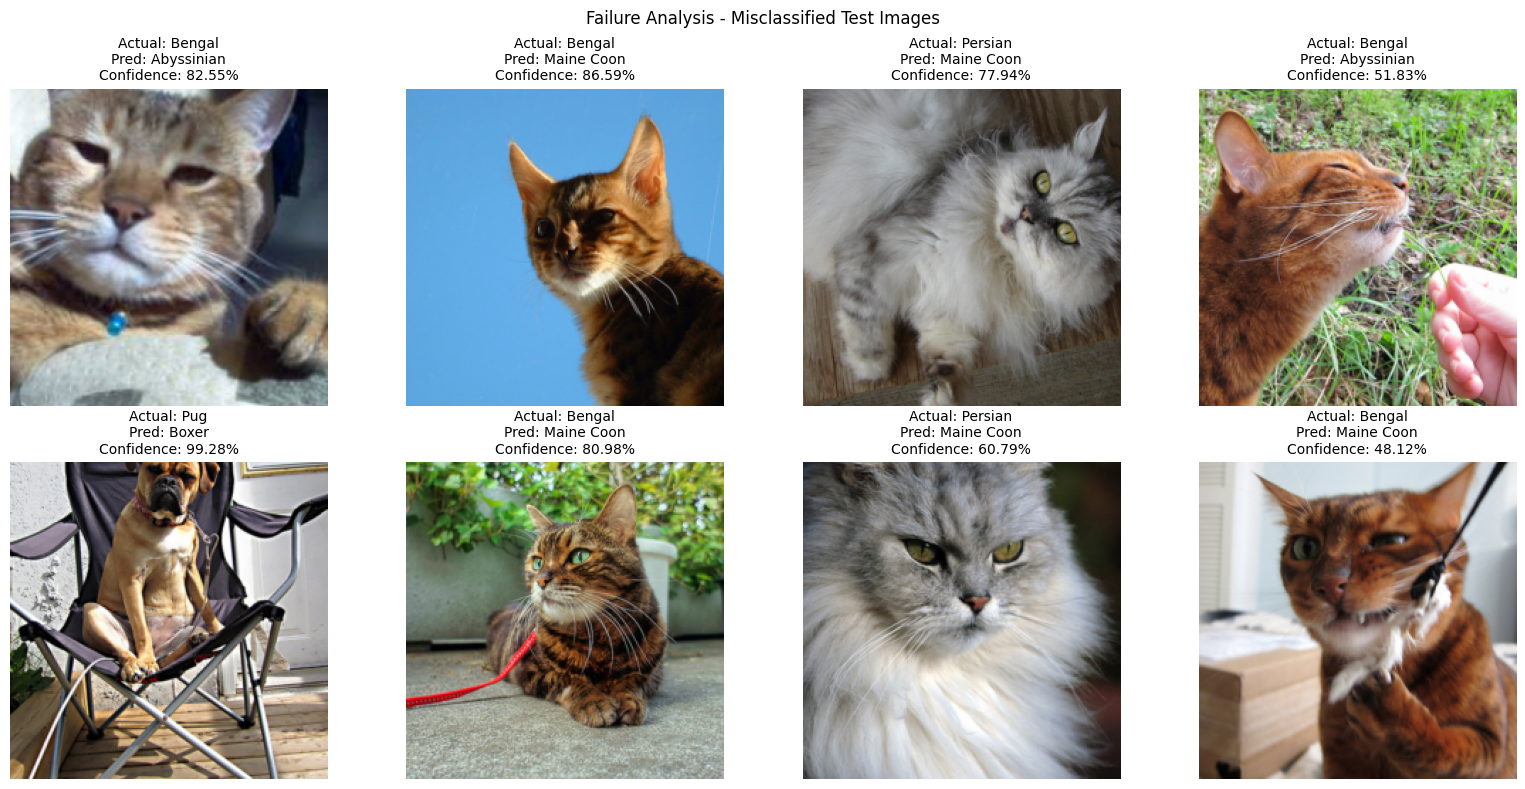

Total misclassified: 8


In [32]:
## model terbaik B5
import torch
import matplotlib.pyplot as plt

model.eval()

wrong_samples = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        confidence, predictions = probs.max(dim=1)

        for i in range(len(labels)):
            if predictions[i] != labels[i]:
                wrong_samples.append((
                    images[i].cpu(),
                    labels[i].item(),
                    predictions[i].item(),
                    confidence[i].item()
                ))

# Tampilkan maksimal 8 gambar salah prediksi
samples = wrong_samples[:8]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(
    2, 4, figsize=(16, 8)
)

for ax in axes.flat:
    ax.axis("off")

for ax, (image, actual, pred, conf) in zip(axes.flat, samples):
    image = (image * std + mean).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))

    ax.set_title(
        f"Actual: {selected_classes[actual]}\n"
        f"Pred: {selected_classes[pred]}\n"
        f"Confidence: {conf:.2%}",
        fontsize=10
    )

plt.suptitle("Failure Analysis - Misclassified Test Images")
plt.tight_layout()
plt.show()

print(f"Total misclassified: {len(wrong_samples)}")

#### **Fine-Tuning ResNet18 with Learning Rate Scheduler (NOTE: B6 hanyalah code untuk point acuan LLM).**

Trainable Parameters: 8,398,858
Epoch 01/20 | Train Loss: 0.7657 | Train Acc: 78.88% | Val Loss: 0.1326 | Val Acc: 96.66% | LR: 0.0001000 / 0.0010000
Epoch 02/20 | Train Loss: 0.1703 | Train Acc: 96.28% | Val Loss: 0.1072 | Val Acc: 97.32% | LR: 0.0001000 / 0.0010000
Epoch 03/20 | Train Loss: 0.0891 | Train Acc: 97.71% | Val Loss: 0.1073 | Val Acc: 96.32% | LR: 0.0001000 / 0.0010000
Epoch 04/20 | Train Loss: 0.0559 | Train Acc: 99.07% | Val Loss: 0.0995 | Val Acc: 96.99% | LR: 0.0001000 / 0.0010000
Epoch 05/20 | Train Loss: 0.0574 | Train Acc: 98.35% | Val Loss: 0.0942 | Val Acc: 97.66% | LR: 0.0001000 / 0.0010000
Epoch 06/20 | Train Loss: 0.0348 | Train Acc: 99.28% | Val Loss: 0.0949 | Val Acc: 96.99% | LR: 0.0001000 / 0.0010000
Epoch 07/20 | Train Loss: 0.0222 | Train Acc: 99.71% | Val Loss: 0.1074 | Val Acc: 96.66% | LR: 0.0001000 / 0.0010000
Epoch 08/20 | Train Loss: 0.0275 | Train Acc: 99.43% | Val Loss: 0.1092 | Val Acc: 96.99% | LR: 0.0001000 / 0.0010000
Epoch 09/20 | Train Loss

,Eksperimen,Strategi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Training (s),Validation Accuracy,Macro F1 Test
0,B6,ResNet18 Fine-Tuning + LR Scheduler,8398858,1e-4 / 1e-3 (ReduceLROnPlateau),5,162.22,97.66%,0.9492


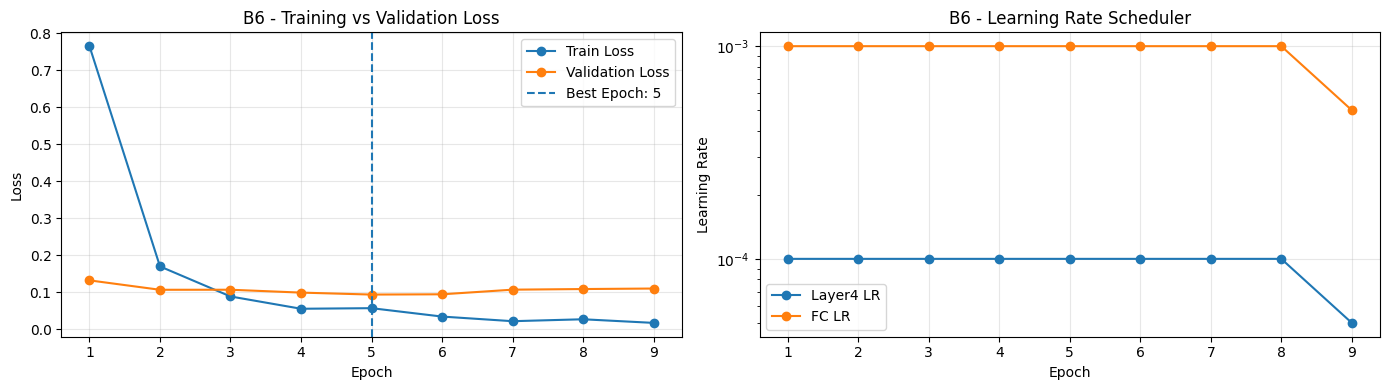


Saved:
- resnet18_b6_scheduler.pth
- B6_scheduler_analysis.png
- B6_metrics.csv


In [39]:
# ============================================================
# B6 — RESNET18 FINE-TUNING WITH LR SCHEDULER
# ============================================================

import time
import copy
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

from torchvision import models
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. MODEL INITIALIZATION
# ------------------------------------------------------------

weights_b6 = models.ResNet18_Weights.IMAGENET1K_V1
model_b6 = models.resnet18(weights=weights_b6)

# Freeze seluruh backbone
for param in model_b6.parameters():
    param.requires_grad = False

# Ganti classifier untuk 10 kelas
model_b6.fc = nn.Linear(
    model_b6.fc.in_features,
    len(selected_classes)
)

# Unfreeze layer4
for param in model_b6.layer4.parameters():
    param.requires_grad = True

model_b6 = model_b6.to(device)

trainable_params_b6 = sum(
    p.numel()
    for p in model_b6.parameters()
    if p.requires_grad
)

print(f"Trainable Parameters: {trainable_params_b6:,}")


# ------------------------------------------------------------
# 2. LOSS, OPTIMIZER, SCHEDULER
# ------------------------------------------------------------

criterion_b6 = nn.CrossEntropyLoss()

optimizer_b6 = torch.optim.AdamW([
    {
        "params": model_b6.layer4.parameters(),
        "lr": 1e-4
    },
    {
        "params": model_b6.fc.parameters(),
        "lr": 1e-3
    }
], weight_decay=1e-2)

scheduler_b6 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_b6,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)


# ------------------------------------------------------------
# 3. TRAINING CONFIGURATION
# ------------------------------------------------------------

epochs = 20
patience = 4

best_val_loss = float("inf")
best_epoch = 0
counter = 0

history_b6 = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr_layer4": [],
    "lr_fc": []
}

best_weights_b6 = copy.deepcopy(model_b6.state_dict())

start_time = time.time()


# ------------------------------------------------------------
# 4. TRAINING LOOP
# ------------------------------------------------------------

for epoch in range(epochs):

    # TRAINING
    model_b6.train()

    # Frozen backbone menggunakan pretrained BN statistics
    model_b6.bn1.eval()
    model_b6.layer1.eval()
    model_b6.layer2.eval()
    model_b6.layer3.eval()

    train_loss = 0
    train_correct = 0

    # Sama seperti B3: training dengan augmentasi
    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_b6.zero_grad()

        outputs = model_b6(images)
        loss = criterion_b6(outputs, labels)

        loss.backward()
        optimizer_b6.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct / len(train_loader.dataset)

    # VALIDATION
    model_b6.eval()

    val_loss = 0
    val_correct = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_b6(images)
            loss = criterion_b6(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(1) == labels
            ).sum().item()

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct / len(val_loader.dataset)

    # SAVE METRICS
    history_b6["train_loss"].append(train_loss)
    history_b6["train_acc"].append(train_acc)
    history_b6["val_loss"].append(val_loss)
    history_b6["val_acc"].append(val_acc)

    # Simpan LR yang digunakan pada epoch ini
    history_b6["lr_layer4"].append(
        optimizer_b6.param_groups[0]["lr"]
    )
    history_b6["lr_fc"].append(
        optimizer_b6.param_groups[1]["lr"]
    )

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"LR: {optimizer_b6.param_groups[0]['lr']:.7f} / "
        f"{optimizer_b6.param_groups[1]['lr']:.7f}"
    )

    # LEARNING RATE SCHEDULER
    scheduler_b6.step(val_loss)

    # EARLY STOPPING
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_weights_b6 = copy.deepcopy(
            model_b6.state_dict()
        )

        best_epoch = epoch + 1
        counter = 0

    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break


# ------------------------------------------------------------
# 5. RESTORE AND SAVE BEST MODEL
# ------------------------------------------------------------

training_time_b6 = time.time() - start_time
best_epoch_b6 = best_epoch

model_b6.load_state_dict(best_weights_b6)
model_b6.eval()

torch.save(
    model_b6.state_dict(),
    "resnet18_b6_scheduler.pth"
)

print(f"\nBest Epoch: {best_epoch_b6}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time_b6:.2f} seconds")


# ------------------------------------------------------------
# 6. TEST EVALUATION
# ------------------------------------------------------------

y_true_b6 = []
y_pred_b6 = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_b6(images)
        predictions = outputs.argmax(1)

        y_true_b6.extend(labels.cpu().numpy())
        y_pred_b6.extend(predictions.cpu().numpy())

test_acc_b6 = accuracy_score(y_true_b6, y_pred_b6)
macro_f1_b6 = f1_score(
    y_true_b6,
    y_pred_b6,
    average="macro"
)

print(f"\nTest Accuracy: {test_acc_b6:.2%}")
print(f"Test Macro F1: {macro_f1_b6:.4f}")


# ------------------------------------------------------------
# 7. RESULT SUMMARY
# ------------------------------------------------------------

result_B6 = {
    "Eksperimen": "B6",
    "Strategi": "ResNet18 Fine-Tuning + LR Scheduler",
    "Trainable Params": trainable_params_b6,
    "Learning Rate": "1e-4 / 1e-3 (ReduceLROnPlateau)",
    "Epoch Konvergen": best_epoch_b6,
    "Waktu Training (s)": round(training_time_b6, 2),
    "Validation Accuracy": (
        f"{history_b6['val_acc'][best_epoch_b6-1]:.2%}"
    ),
    "Macro F1 Test": round(macro_f1_b6, 4)
}

display(pd.DataFrame([result_B6]))


# ------------------------------------------------------------
# 8. VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

epoch_range = range(1, len(history_b6["train_loss"]) + 1)

# Loss
axes[0].plot(
    epoch_range,
    history_b6["train_loss"],
    marker="o",
    label="Train Loss"
)

axes[0].plot(
    epoch_range,
    history_b6["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].axvline(
    best_epoch_b6,
    linestyle="--",
    label=f"Best Epoch: {best_epoch_b6}"
)

axes[0].set_title("B6 - Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Learning Rate
axes[1].plot(
    epoch_range,
    history_b6["lr_layer4"],
    marker="o",
    label="Layer4 LR"
)

axes[1].plot(
    epoch_range,
    history_b6["lr_fc"],
    marker="o",
    label="FC LR"
)

axes[1].set_yscale("log")
axes[1].set_title("B6 - Learning Rate Scheduler")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Learning Rate")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "B6_scheduler_analysis.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 9. EXPORT TRAINING LOG
# ------------------------------------------------------------

df_b6 = pd.DataFrame(history_b6)
df_b6.insert(
    0,
    "epoch",
    range(1, len(df_b6) + 1)
)

df_b6.to_csv("B6_metrics.csv", index=False)

print("\nSaved:")
print("- resnet18_b6_scheduler.pth")
print("- B6_scheduler_analysis.png")
print("- B6_metrics.csv")

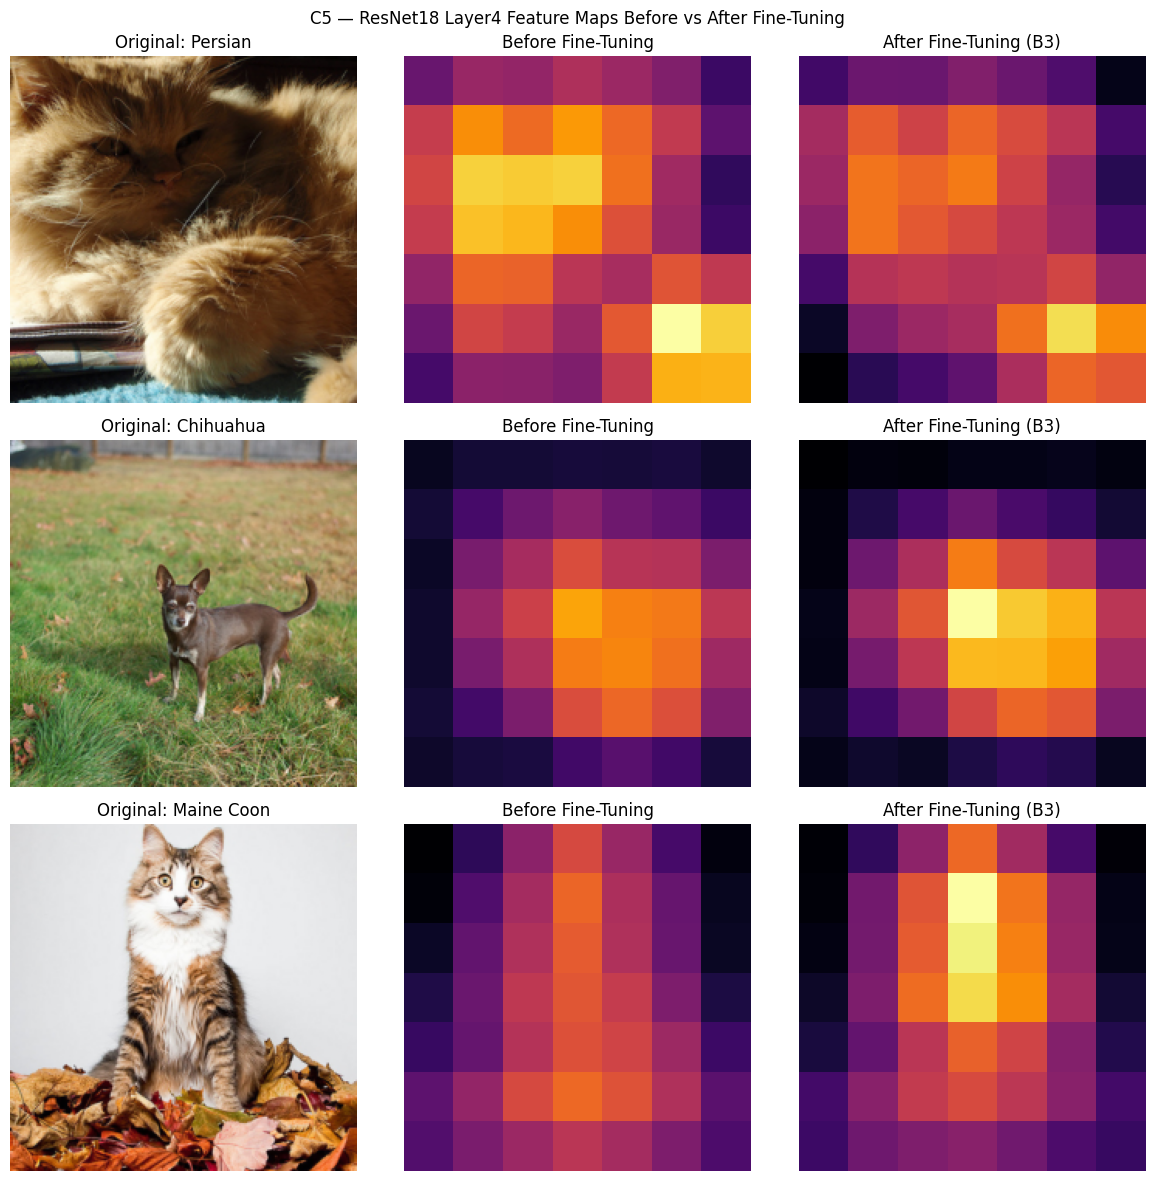

In [40]:
import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import models

checkpoint = "resnet18_b3_finetuned.pth"

if not os.path.exists(checkpoint):
    raise FileNotFoundError(
        "Checkpoint B3 tidak ditemukan. Jalankan kembali "
        "cell training dan penyimpanan checkpoint B3."
    )

# Before: pretrained ImageNet
before = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)
before.fc = nn.Linear(before.fc.in_features, 10)

# After: hasil fine-tuning B3
after = models.resnet18(weights=None)
after.fc = nn.Linear(after.fc.in_features, 10)
after.load_state_dict(
    torch.load(checkpoint, map_location="cpu", weights_only=True)
)

before = before.to(device).eval()
after = after.to(device).eval()

def get_feature_map(net, img):
    captured = []

    def hook(module, inputs, output):
        captured.append(output.detach().cpu())

    handle = net.layer4.register_forward_hook(hook)

    with torch.no_grad():
        net(img.unsqueeze(0).to(device))

    handle.remove()
    return captured[0][0].mean(dim=0).numpy()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Gunakan 3 gambar test yang sama untuk kedua model
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, idx in enumerate([0, 1, 2]):
    image, label = test_dataset[idx]

    original = (image.cpu() * std + mean).clamp(0, 1)
    fmap_before = get_feature_map(before, image)
    fmap_after = get_feature_map(after, image)

    vmin = min(fmap_before.min(), fmap_after.min())
    vmax = max(fmap_before.max(), fmap_after.max())

    axes[row, 0].imshow(original.permute(1, 2, 0))
    axes[row, 0].set_title(
        f"Original: {selected_classes[label]}"
    )

    axes[row, 1].imshow(
        fmap_before, cmap="inferno", vmin=vmin, vmax=vmax
    )
    axes[row, 1].set_title("Before Fine-Tuning")

    axes[row, 2].imshow(
        fmap_after, cmap="inferno", vmin=vmin, vmax=vmax
    )
    axes[row, 2].set_title("After Fine-Tuning (B3)")

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "C5 — ResNet18 Layer4 Feature Maps Before vs After Fine-Tuning"
)
plt.tight_layout()
plt.savefig(
    "C5_feature_maps.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()